# Actividad 5 — UrbanOS ML: entrenamiento, ajuste y comparación de modelos

Clasificación binaria de imágenes de calles (`bache` = 1, `sin_dano` = 0) a partir de 16 características tabulares.
Se comparan **regresión logística** y **Random Forest** con `GridSearchCV` (validación cruzada estratificada de 5 folds) y se registra todo en **MLflow**.

Este notebook documenta el flujo completo leyendo los archivos que ya generaron `datos_prep.py` y `train.py`; **no reentrena** salvo que se active `REENTRENAR` en la primera celda de código.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos" / "datos_limp").exists())
DATOS = RAIZ / "datos"
RESULTADOS = RAIZ / "resultados"
EVIDENCIAS = RAIZ / "evidencias"

EXPERIMENTO = "UrbanOS_Actividad5_Clasificacion"
MLFLOW_URI = "http://127.0.0.1:5000"
MODELOS = ["regresion_logistica", "random_forest"]
REENTRENAR = False  

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def mostrar(ruta, ancho=700):
    display(Image(filename=str(ruta), width=ancho))


print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Users\Eduardo\Desktop\Dev\Proyectos\urbanos\ml\actividad5


## 1. Datos: origen, versión y limpieza

Fuente: *Pothole Detection Dataset* (Atulya Kumar, Kaggle, licencia CC0 según la página), descargado el 10 de octubre de 2026.
Las imágenes no se versionan en el repositorio; se versiona el inventario con las características de cada una.

In [2]:
version = json.loads((DATOS / "datos_limp" / "version.json").read_text(encoding="utf-8"))
reporte = version["reporte"]
print("Versión:", version["version"], "| fecha:", version["fecha"])
print("SHA-256:", version["sha256"])
print("Filas:", reporte["filas_iniciales"], "->", reporte["filas_finales"])
print("Eliminadas por regla:", reporte["eliminadas_por_regla"])
print("Umbrales:", reporte["umbrales"])
pd.DataFrame({"inicial": reporte["balance_inicial"], "final": reporte["balance_final"]})

Versión: v1-71d200e2 | fecha: 2026-10-17
SHA-256: 71d200e2cc456e0dd75c761b7e5ddaa633aff8fcce903dd40e2f20946066e64d
Filas: 681 -> 668
Eliminadas por regla: {'casi_duplicada': 8, 'duplicada_exacta': 5}
Umbrales: {'lado_minimo_px': 64, 'relacion_aspecto_maxima': 4.0, 'distancia_hamming_casi_duplicadas': 4, 'factor_iqr_atipicos': 1.5}


,inicial,final
sin_dano,352,341
bache,329,327


In [3]:
original = pd.read_csv(DATOS / "datos_ini" / "dataset_original.csv")
limpio = pd.read_csv(DATOS / "datos_limp" / "dataset_limpio.csv")
eliminadas = pd.read_csv(DATOS / "datos_limp" / "filas_eliminadas.csv")

print("Original:", original.shape, "| Limpio:", limpio.shape, "| Eliminadas:", eliminadas.shape)
print("\nMotivos de eliminación:")
display(eliminadas["motivo"].value_counts().to_frame("registros"))
print("Valores nulos en el dataset limpio:", int(limpio.isna().sum().sum()))
print("Duplicados exactos (md5) en el dataset limpio:", int(limpio["md5"].duplicated().sum()))
display(limpio["clase"].value_counts().to_frame("registros"))

Original: (681, 26) | Limpio: (668, 26) | Eliminadas: (13, 27)

Motivos de eliminación:


,registros
motivo,
casi_duplicada,8
duplicada_exacta,5


Valores nulos en el dataset limpio: 0
Duplicados exactos (md5) en el dataset limpio: 0


,registros
clase,
sin_dano,341
bache,327


In [4]:
diccionario = pd.read_csv(DATOS / "datos_limp" / "diccionario_datos.csv")
diccionario

,campo,tipo,descripcion
0,ruta_relativa,texto,Ruta de la imagen dentro de la carpeta de imág...
1,clase,texto,"Clase original, deducida de la carpeta: 'bache..."
2,etiqueta,entero,"Clase codificada: 1 = bache, 0 = sin_dano."
3,md5,texto,Huella exacta del archivo; detecta duplicados ...
4,huella,texto,Huella perceptual (dHash de 64 bits); detecta ...
5,ancho_px,entero,Ancho original en píxeles.
6,alto_px,entero,Alto original en píxeles.
7,relacion_aspecto,decimal,Ancho dividido entre alto.
8,tamano_kb,decimal,Peso del archivo en kilobytes.
9,rojo_media,decimal,Promedio del canal rojo (0 a 1).


## 2. Características usadas por los modelos

Se toman de la tabla de importancia de variables generada por el entrenamiento, para no duplicar la lista que ya vive en `train.py`.

In [5]:
importancia = pd.read_csv(RESULTADOS / "random_forest_importancia_variables.csv")
CARACTERISTICAS = importancia["caracteristica"].tolist()
print(len(CARACTERISTICAS), "características:")
print(CARACTERISTICAS)
limpio[CARACTERISTICAS].describe().T.round(4)

16 características:
['saturacion_media', 'azul_desv', 'nitidez', 'textura_bloques', 'rojo_desv', 'verde_desv', 'azul_media', 'proporcion_clara', 'entropia', 'densidad_bordes', 'brillo_desv', 'rojo_media', 'contraste', 'proporcion_oscura', 'verde_media', 'brillo_media']


,count,mean,std,min,25%,50%,75%,max
saturacion_media,668.0,0.1928,0.1295,0.0000,0.0987,0.1614,0.2591,0.8385
azul_desv,668.0,0.2048,0.0611,0.0588,0.1602,0.2010,0.2454,0.3754
nitidez,668.0,0.0171,0.0098,0.0013,0.0102,0.0150,0.0218,0.0744
textura_bloques,668.0,0.0685,0.0189,0.0166,0.0553,0.0666,0.0800,0.1347
rojo_desv,668.0,0.1910,0.0512,0.0561,0.1553,0.1892,0.2232,0.3615
verde_desv,668.0,0.1870,0.0508,0.0573,0.1518,0.1847,0.2223,0.3558
azul_media,668.0,0.4521,0.1119,0.0557,0.3849,0.4588,0.5237,0.7767
proporcion_clara,668.0,0.1120,0.1176,0.0000,0.0228,0.0706,0.1687,0.6571
entropia,668.0,4.2268,0.3709,2.1384,4.0440,4.2866,4.4788,4.9232
densidad_bordes,668.0,0.1087,0.0571,0.0005,0.0650,0.1002,0.1415,0.3433


## 3. Exploración

Las figuras principales ya se generaron con `datos_prep.py` (carpeta `evidencias/graficas`). Aquí se complementa con las seis características más importantes del Random Forest, separadas por clase.

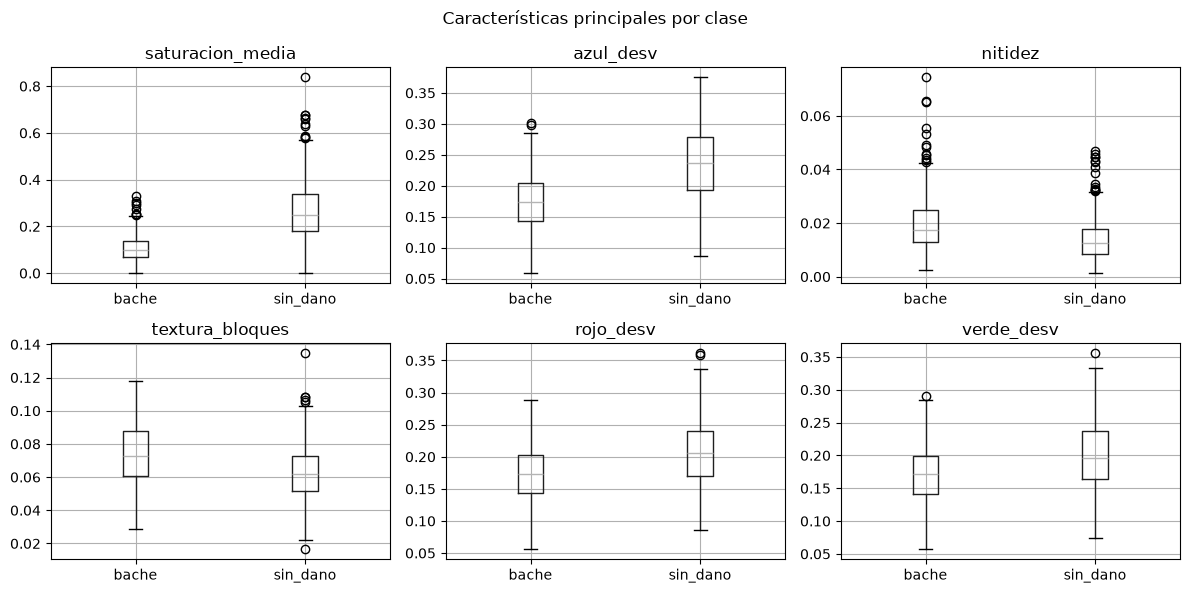

In [6]:
principales = CARACTERISTICAS[:6]
fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
for eje, columna in zip(ejes.ravel(), principales):
    limpio.boxplot(column=columna, by="clase", ax=eje)
    eje.set_title(columna)
    eje.set_xlabel("")
fig.suptitle("Características principales por clase")
plt.tight_layout()
plt.show()

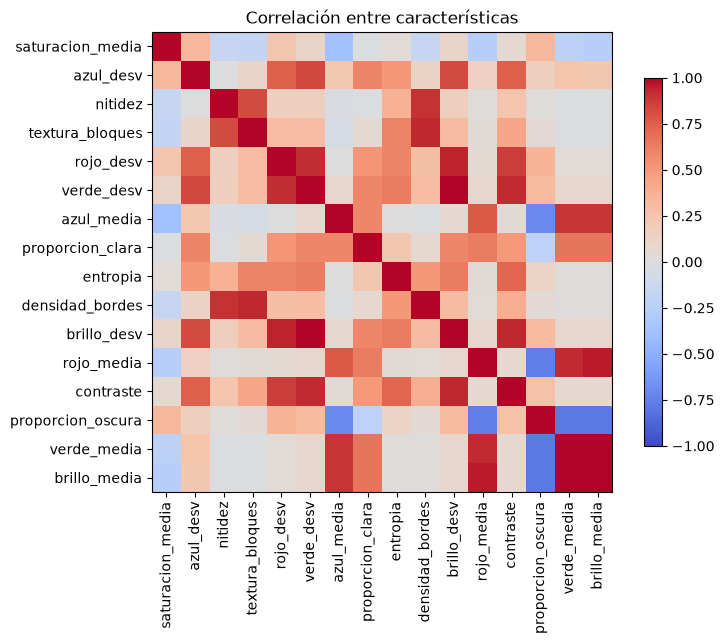

Pares más correlacionados (valor absoluto):


verde_desv       brillo_desv        0.995
verde_media      brillo_media       0.994
rojo_media       brillo_media       0.955
rojo_desv        brillo_desv        0.938
textura_bloques  densidad_bordes    0.935
brillo_desv      contraste          0.931
verde_desv       contraste          0.926
rojo_media       verde_media        0.924
dtype: float64

In [7]:
correlacion = limpio[CARACTERISTICAS].corr()
fig, eje = plt.subplots(figsize=(8, 6.5))
imagen = eje.imshow(correlacion, cmap="coolwarm", vmin=-1, vmax=1)
eje.set_xticks(range(len(CARACTERISTICAS)))
eje.set_xticklabels(CARACTERISTICAS, rotation=90)
eje.set_yticks(range(len(CARACTERISTICAS)))
eje.set_yticklabels(CARACTERISTICAS)
fig.colorbar(imagen, ax=eje, shrink=0.8)
eje.set_title("Correlación entre características")
plt.tight_layout()
plt.show()

pares = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1)).stack()
print("Pares más correlacionados (valor absoluto):")
pares.reindex(pares.abs().sort_values(ascending=False).index).head(8).round(3)

01_motivos_eliminacion.png


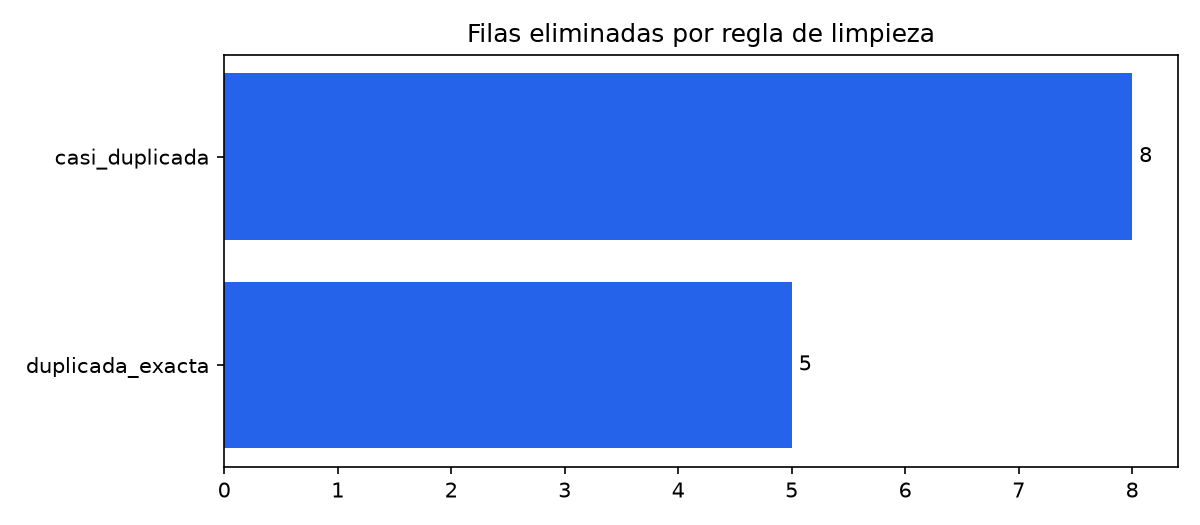

02_balance_clases.png


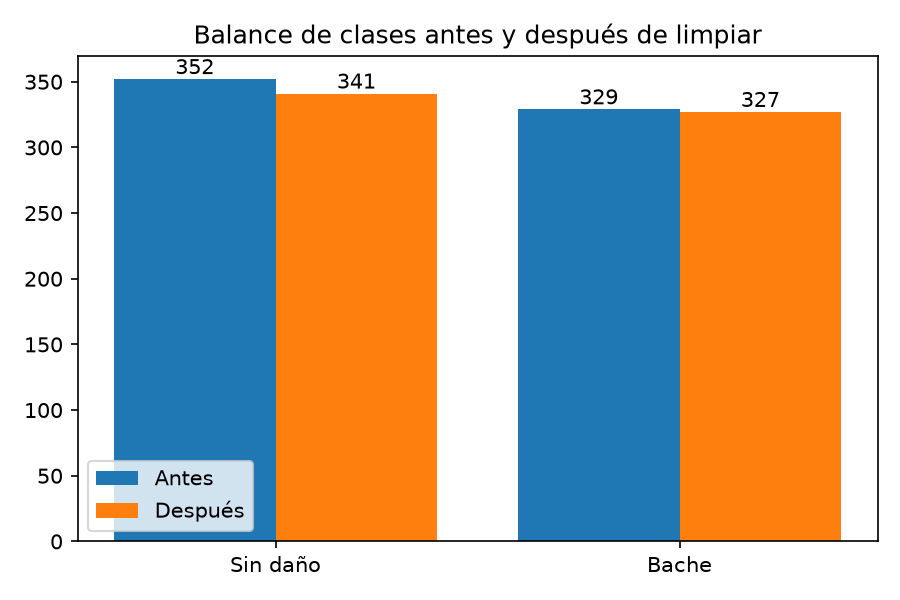

03_distribucion_archivo.png


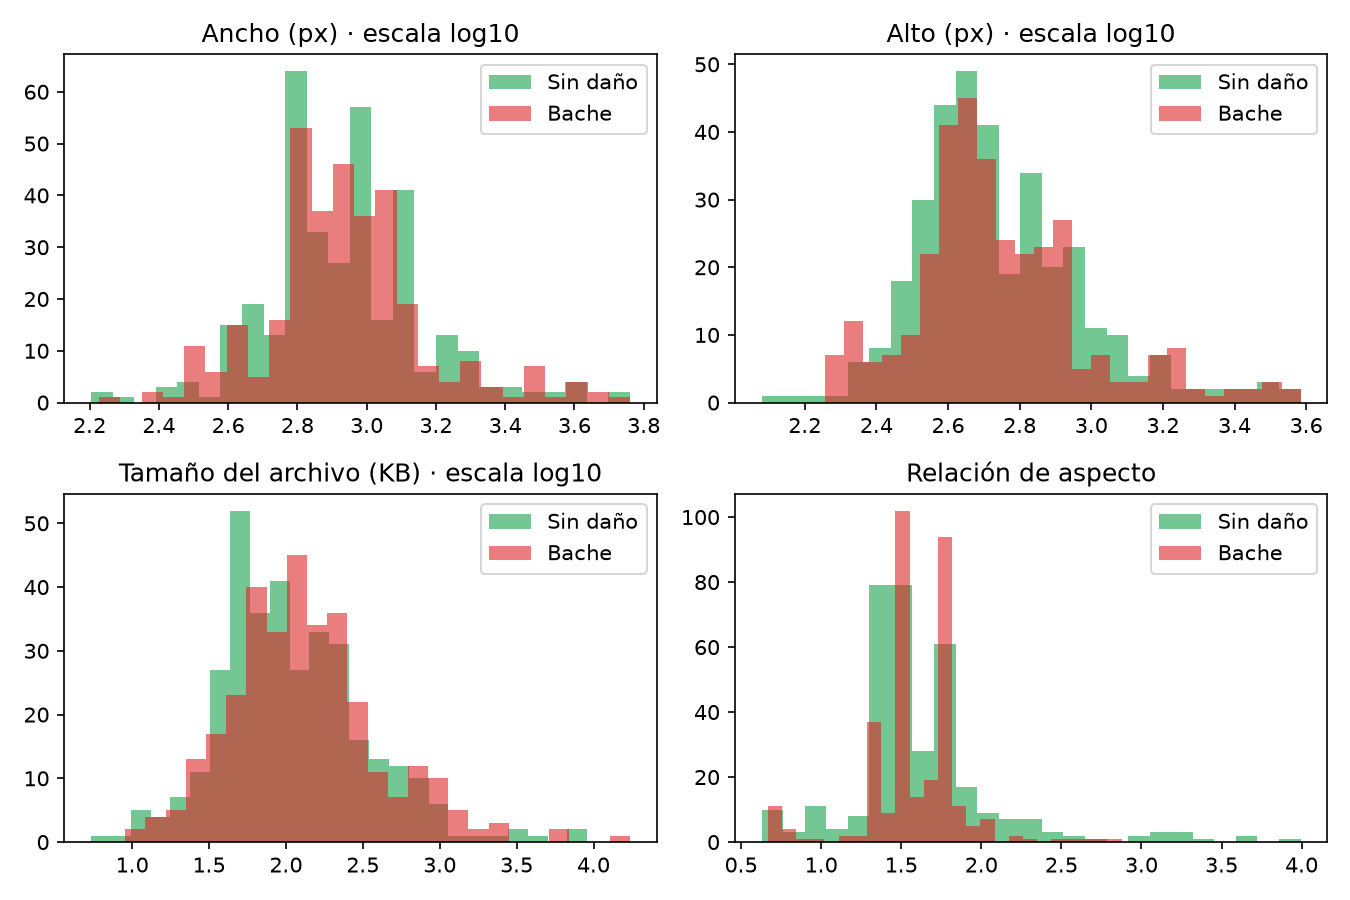

04_caracteristicas_por_clase.png


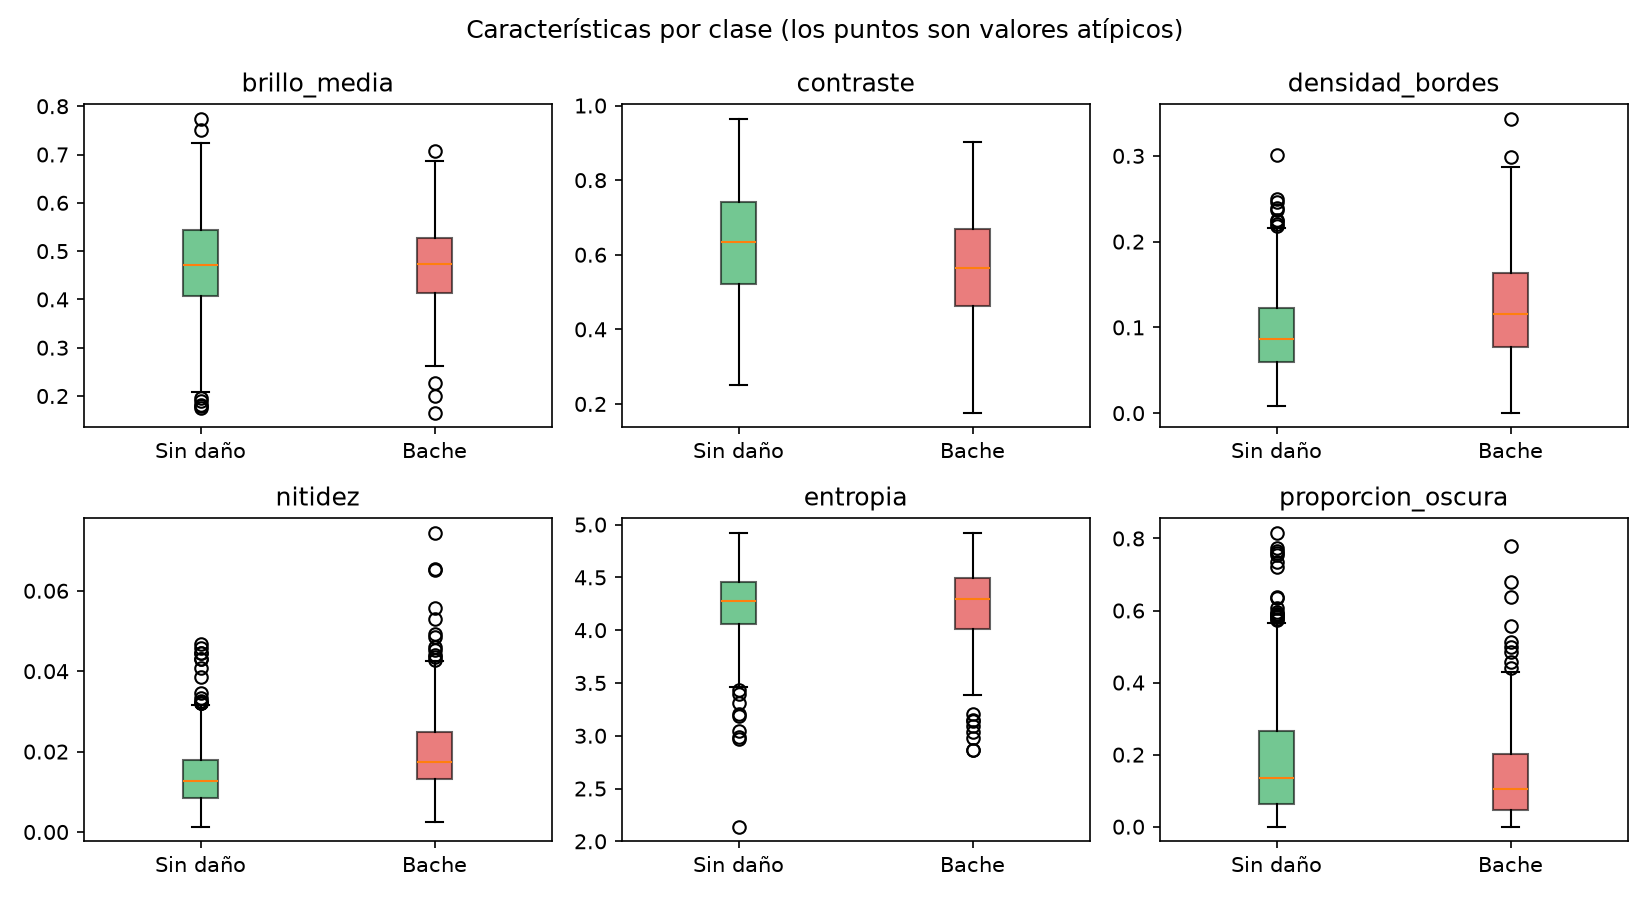

05_correlaciones.png


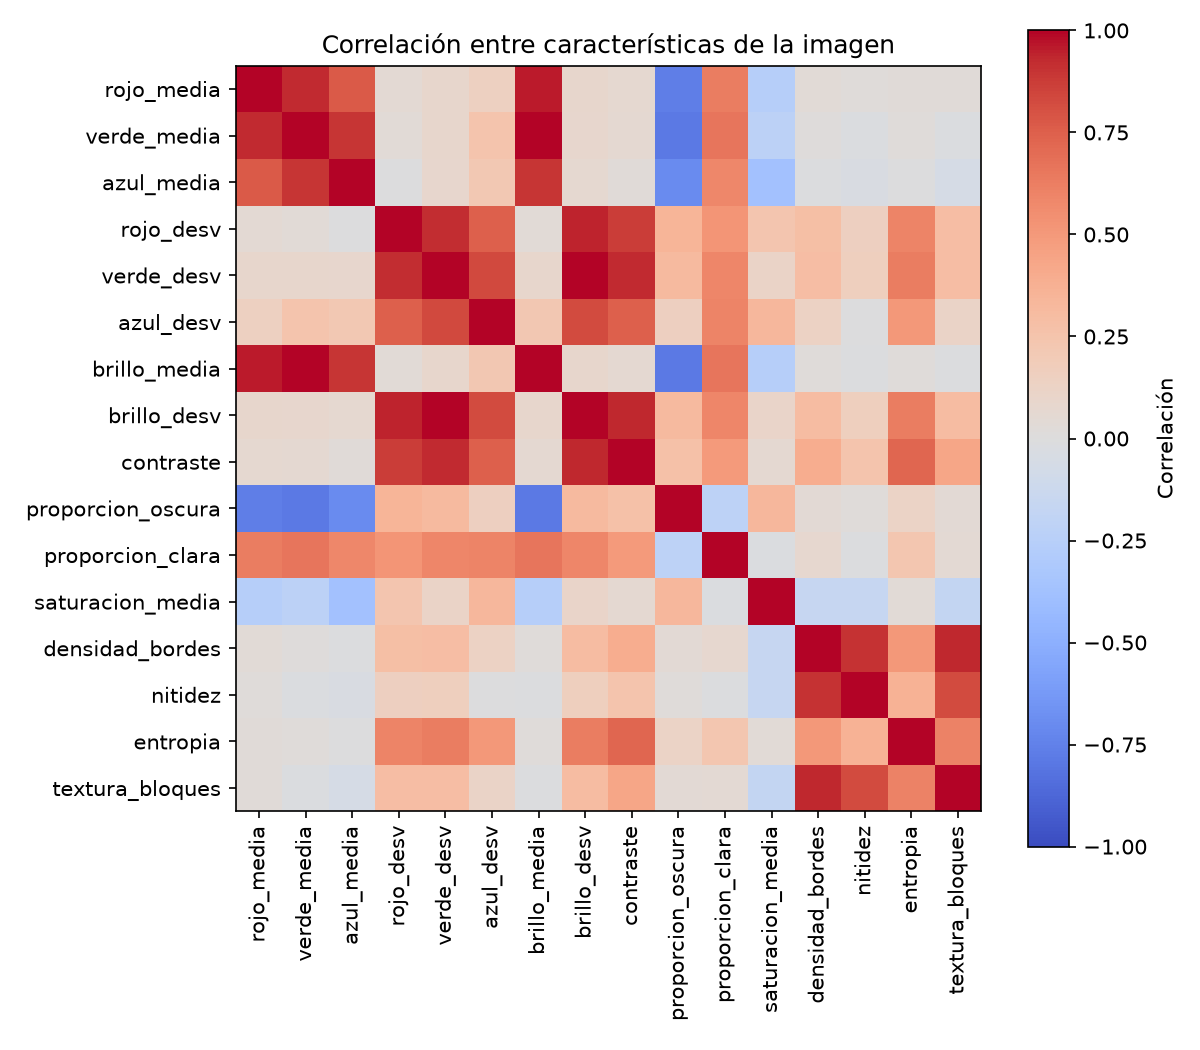

06_pca_clases.png


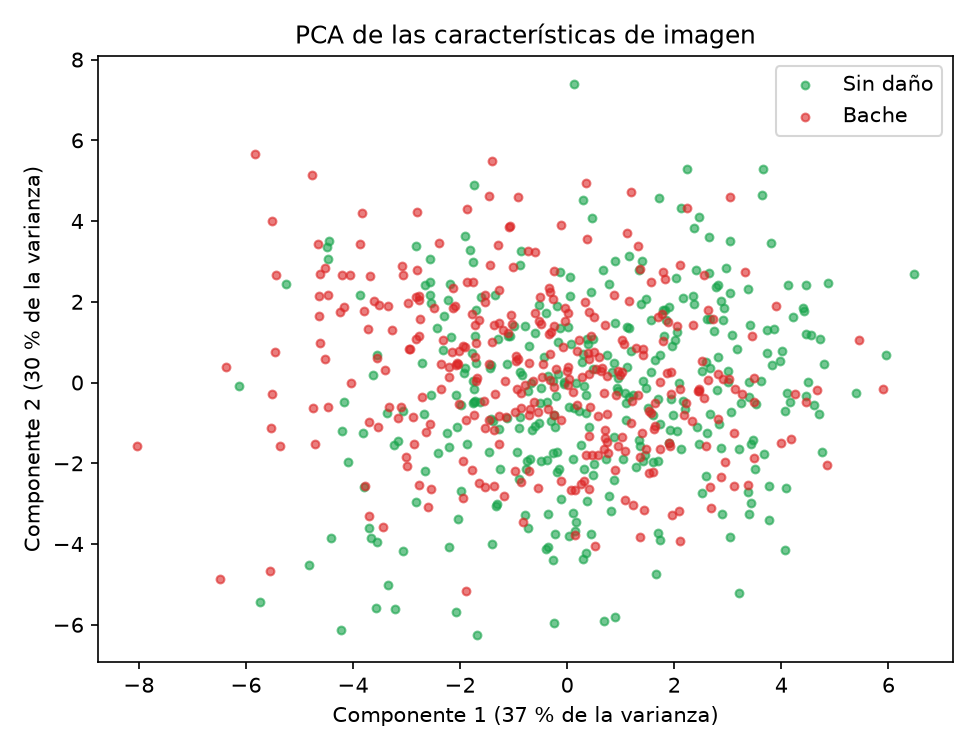

07_atipicos.png


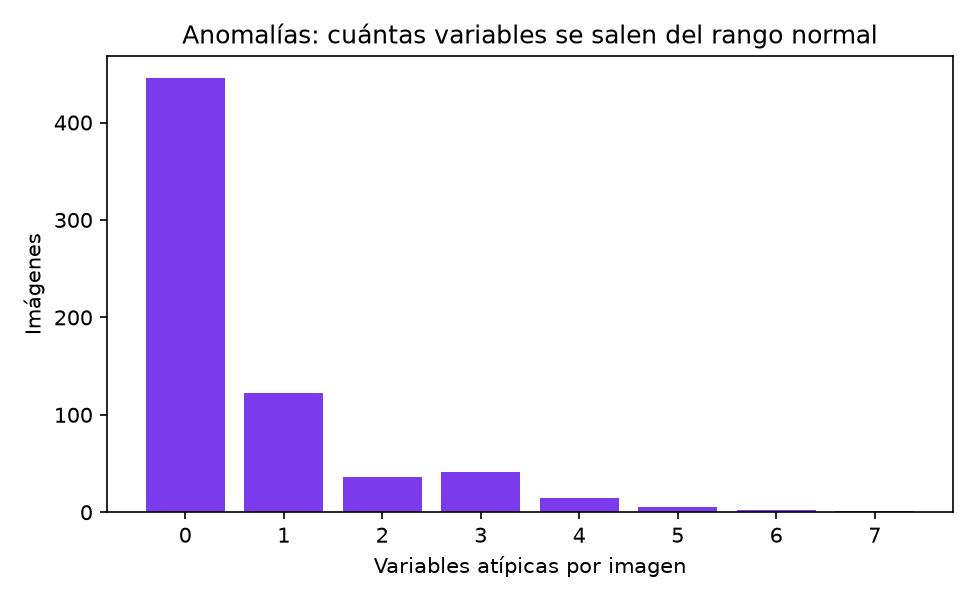

In [8]:
for figura in sorted((EVIDENCIAS / "graficas").glob("*.png")):
    print(figura.name)
    mostrar(figura)

## 4. Entrenamiento y ajuste de hiperparámetros

`fuentes/train.py` ejecuta, para cada algoritmo, una búsqueda `GridSearchCV` con validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento (80 %). La prueba (20 %) se evalúa una sola vez.
Aquí se muestran las mejores combinaciones de cada búsqueda.

In [9]:
comparativo = pd.read_csv(RESULTADOS / "comparativo_modelos.csv")

for nombre in MODELOS:
    cv = pd.read_csv(RESULTADOS / f"{nombre}_resultados_cv.csv")
    if "rank_test_score" in cv.columns:
        cv = cv.sort_values("rank_test_score")
    print(f"{nombre}: {len(cv)} combinaciones evaluadas")
    display(cv.head(5))

print("Mejores hiperparámetros:")
for _, fila in comparativo.iterrows():
    print("-", fila["modelo"], json.loads(fila["mejores_hiperparametros"]))

regresion_logistica: 6 combinaciones evaluadas


,mean_fit_time,std_fit_time,param_clasificador__C,param_clasificador__class_weight,mean_test_score,std_test_score,rank_test_score,mean_train_score,std_train_score
3,0.014506,0.001405,1.0,balanced,0.920551,0.017468,1,0.919108,0.005636
2,0.059491,0.045626,1.0,NaN,0.916533,0.015942,2,0.919223,0.008196
5,0.016557,0.001694,10.0,balanced,0.915035,0.017405,3,0.923568,0.007085
4,0.016203,0.001164,10.0,NaN,0.912903,0.018204,4,0.924441,0.007318
0,0.110602,0.003169,0.1,NaN,0.884248,0.021495,5,0.902881,0.006649


random_forest: 48 combinaciones evaluadas


,mean_fit_time,std_fit_time,param_class_weight,param_max_depth,param_min_samples_leaf,param_min_samples_split,param_n_estimators,mean_test_score,std_test_score,rank_test_score,mean_train_score,std_train_score
35,1.138051,0.135502,balanced,10.0,1,5,400,0.871850,0.043571,1,0.996188,0.001895
8,0.541513,0.134111,NaN,10.0,1,2,200,0.870396,0.035435,2,1.000000,0.000000
16,0.631720,0.155116,NaN,20.0,1,2,200,0.869749,0.040695,3,1.000000,0.000000
0,0.628455,0.091188,NaN,NaN,1,2,200,0.869749,0.040695,3,1.000000,0.000000
9,1.104064,0.218371,NaN,10.0,1,2,400,0.868828,0.040872,5,1.000000,0.000000


Mejores hiperparámetros:
- regresion_logistica {'clasificador__C': 1.0, 'clasificador__class_weight': 'balanced'}
- random_forest {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}


## 5. Evaluación en el conjunto de prueba

Se verifica que las métricas guardadas coinciden con las que se calculan a partir de las matrices de confusión.

In [10]:
def metricas_desde_matriz(nombre):
    matriz = pd.read_csv(RESULTADOS / f"{nombre}_matriz_confusion.csv", index_col=0).to_numpy()
    tn, fp, fn, tp = matriz.ravel()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    return {
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "accuracy": (tp + tn) / matriz.sum(),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall),
    }


filas = []
for nombre in MODELOS:
    desde_matriz = metricas_desde_matriz(nombre)
    guardado = comparativo.loc[comparativo["modelo"] == nombre].iloc[0]
    for metrica in ["accuracy", "precision", "recall", "f1"]:
        assert np.isclose(desde_matriz[metrica], guardado[metrica]), (nombre, metrica)
    filas.append({"modelo": nombre, **desde_matriz, "roc_auc": guardado["roc_auc"]})

print("Las métricas recalculadas coinciden con las registradas.")
tabla = pd.DataFrame(filas).set_index("modelo")
tabla.round(4)

Las métricas recalculadas coinciden con las registradas.


,tn,fp,fn,tp,accuracy,precision,recall,f1,roc_auc
modelo,,,,,,,,,
regresion_logistica,62,6,3,63,0.9328,0.9130,0.9545,0.9333,0.9615
random_forest,61,7,4,62,0.9179,0.8986,0.9394,0.9185,0.9599


In [11]:
comparativo.drop(columns=["run_id", "mejores_hiperparametros"]).round(4)

,modelo,accuracy,precision,recall,f1,roc_auc,cv_f1_media,cv_f1_std,cv_f1_train_media
0,regresion_logistica,0.9328,0.9130,0.9545,0.9333,0.9615,0.9206,0.0175,0.9191
1,random_forest,0.9179,0.8986,0.9394,0.9185,0.9599,0.8718,0.0436,0.9962


## 6. Comparación y análisis de sobreajuste

Se compara el F1 de entrenamiento y el de validación cruzada con el F1 de prueba.

In [12]:
sobreajuste = comparativo.set_index("modelo")[["cv_f1_train_media", "cv_f1_media", "cv_f1_std", "f1"]].copy()
sobreajuste = sobreajuste.rename(columns={"f1": "f1_prueba"})
sobreajuste["brecha_train_vs_validacion"] = sobreajuste["cv_f1_train_media"] - sobreajuste["cv_f1_media"]
sobreajuste.round(4)

,cv_f1_train_media,cv_f1_media,cv_f1_std,f1_prueba,brecha_train_vs_validacion
modelo,,,,,
regresion_logistica,0.9191,0.9206,0.0175,0.9333,-0.0014
random_forest,0.9962,0.8718,0.0436,0.9185,0.1243


In [13]:
estadistica = json.loads((RESULTADOS / "comparacion_estadistica.json").read_text(encoding="utf-8"))
por_fold = pd.DataFrame(estadistica["f1_por_fold"])
por_fold.index = [f"fold {i}" for i in range(1, len(por_fold) + 1)]
por_fold["diferencia (RL - RF)"] = por_fold["regresion_logistica"] - por_fold["random_forest"]
display(por_fold.round(4))

n_folds = len(por_fold)
print("Método:", estadistica["metodo"])
print("p-value:", estadistica["p_value"])
print("Folds en los que la regresión logística supera a Random Forest:", int((por_fold["diferencia (RL - RF)"] > 0).sum()), "de", n_folds)
print(f"Valor p mínimo posible con {n_folds} folds (bilateral exacto): {2 / 2 ** n_folds}")
print("Interpretación:", estadistica["interpretacion"])
print("Advertencia:", estadistica["advertencia"])

,regresion_logistica,random_forest,diferencia (RL - RF)
fold 1,0.9159,0.8598,0.0561
fold 2,0.9444,0.9259,0.0185
fold 3,0.9159,0.8824,0.0335
fold 4,0.9333,0.8952,0.0381
fold 5,0.8932,0.7959,0.0973


Método: Wilcoxon pareado bilateral sobre F1 por fold
p-value: 0.0625
Folds en los que la regresión logística supera a Random Forest: 5 de 5
Valor p mínimo posible con 5 folds (bilateral exacto): 0.0625
Interpretación: No se detectó una diferencia estadísticamente significativa al nivel 0.05. Esto no demuestra que los modelos sean iguales.
Advertencia: Solo hay cinco folds y los mejores hiperparámetros se seleccionaron con esos folds; el resultado es exploratorio, no concluyente.


comparativo_metricas.png


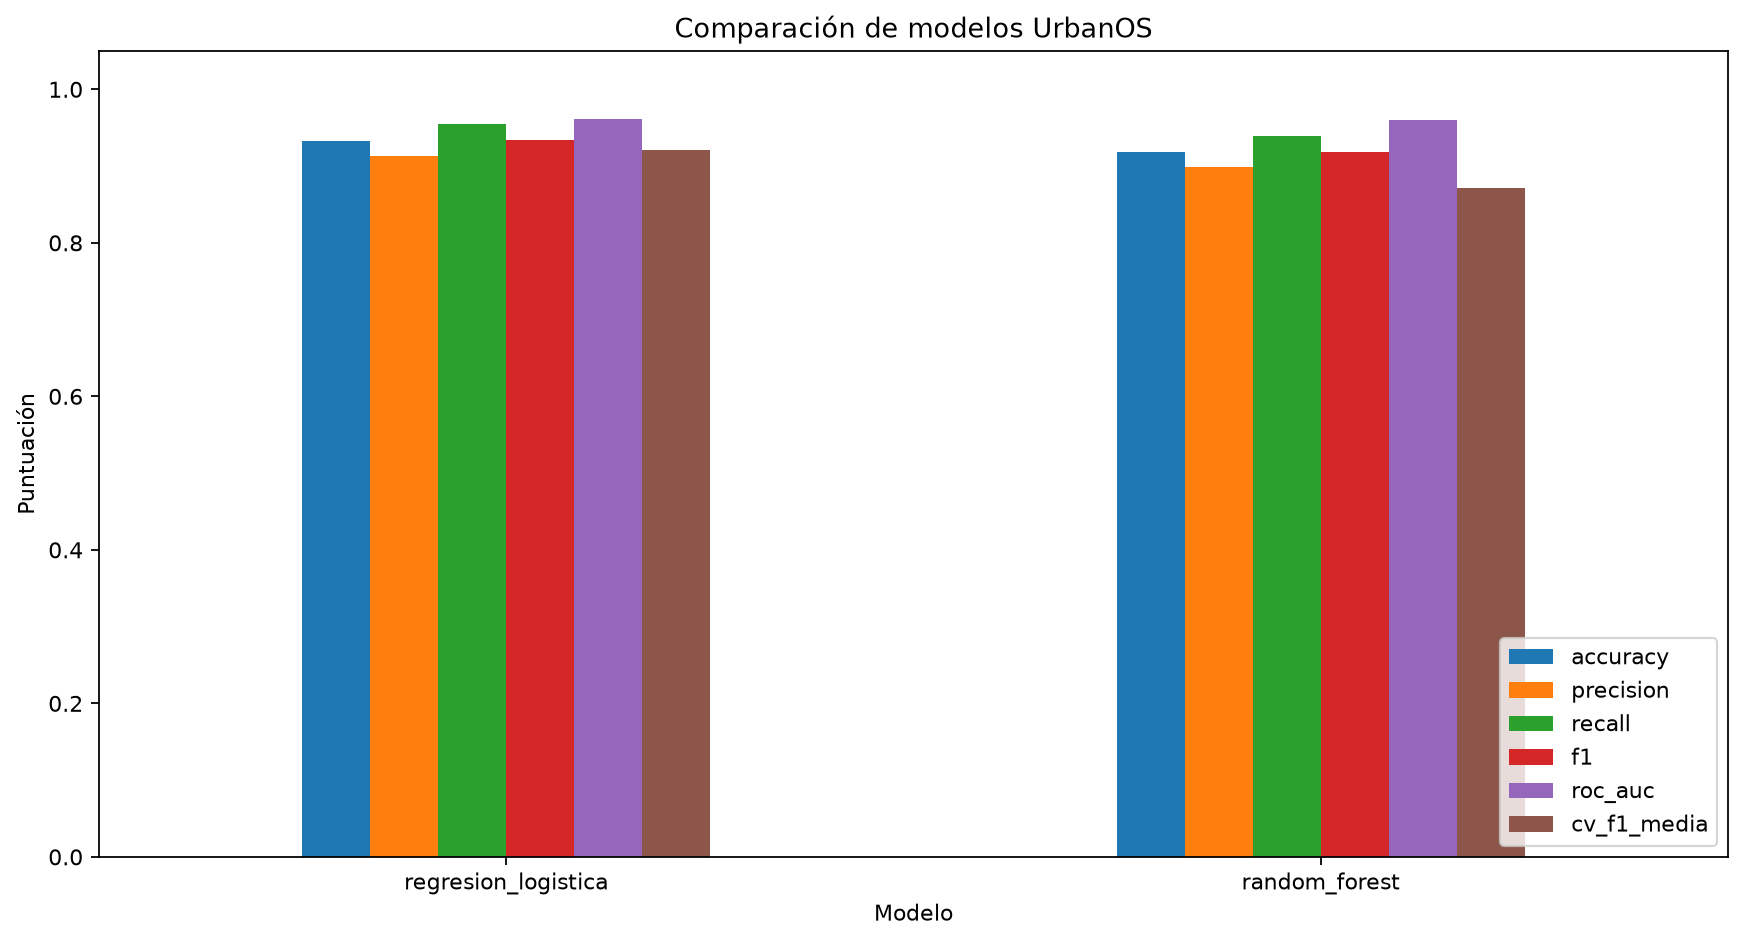

random_forest_curva_roc.png


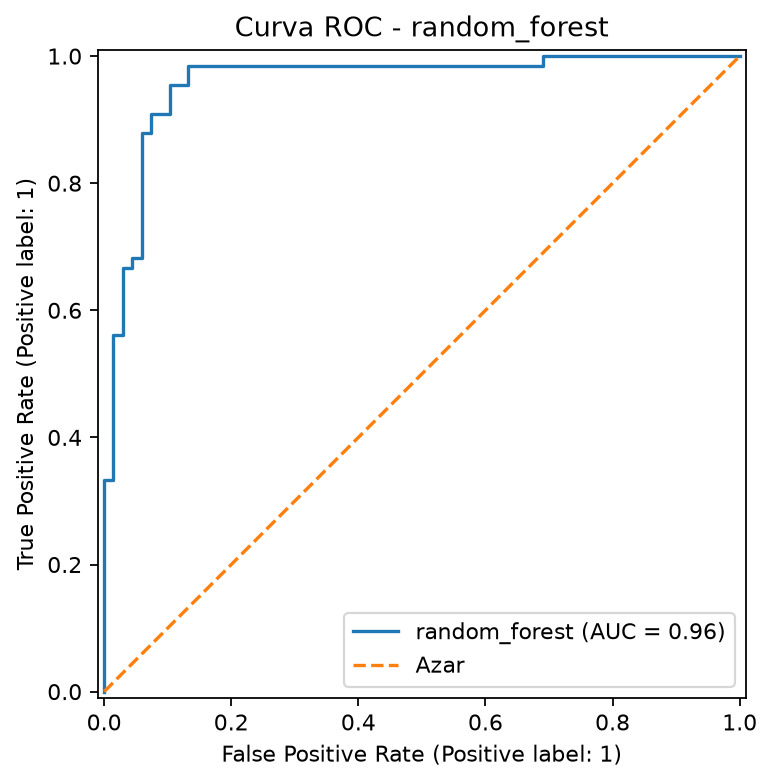

random_forest_importancia_variables.png


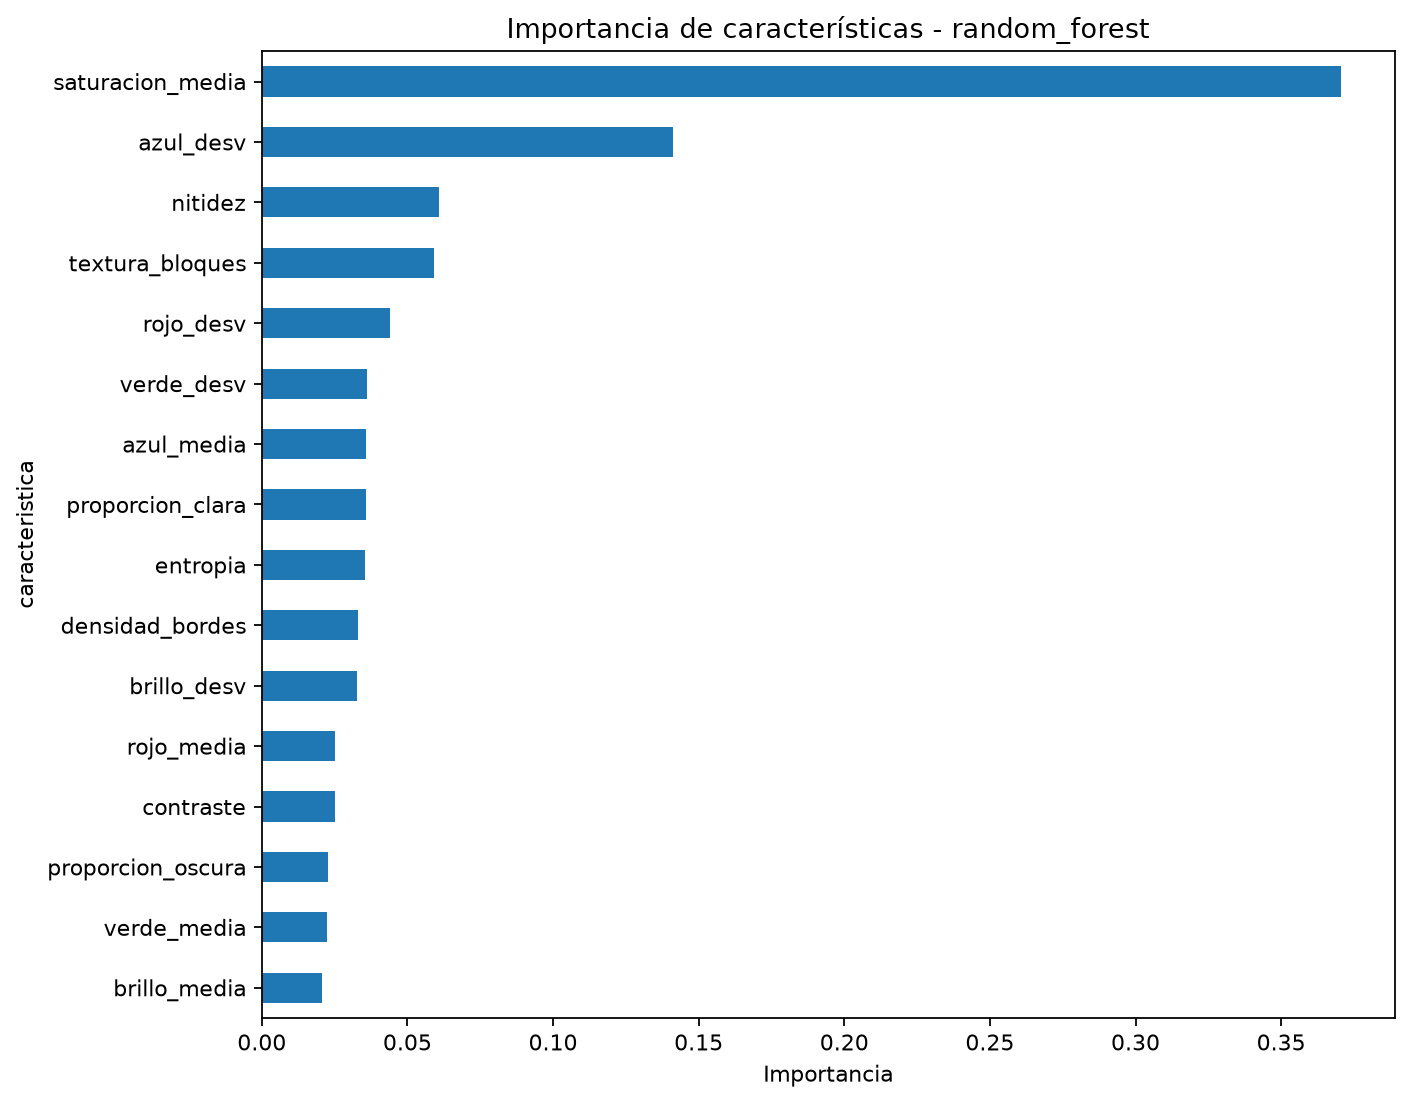

random_forest_matriz_confusion.png


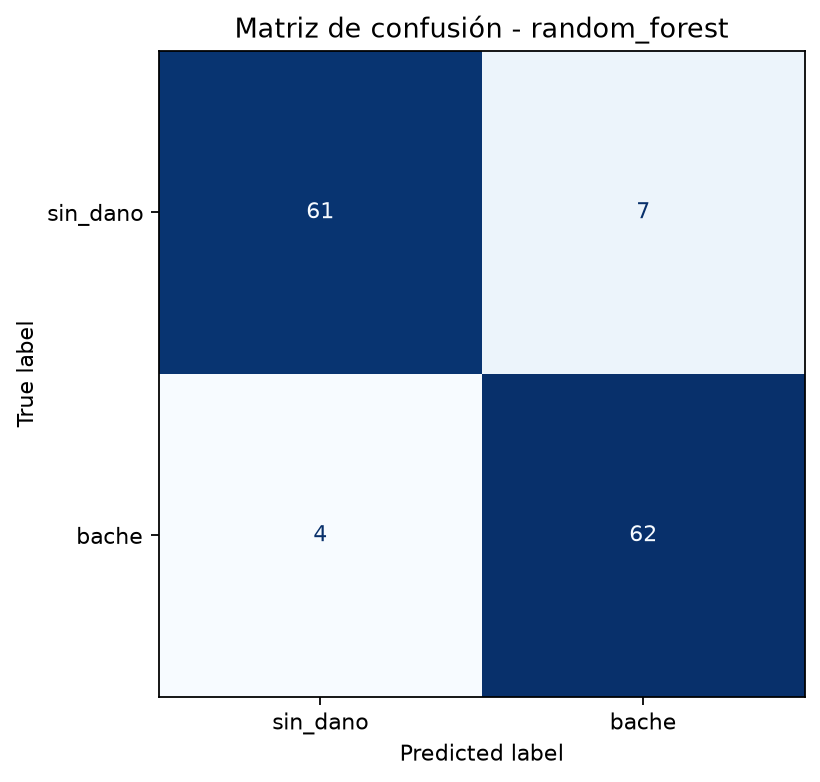

regresion_logistica_curva_roc.png


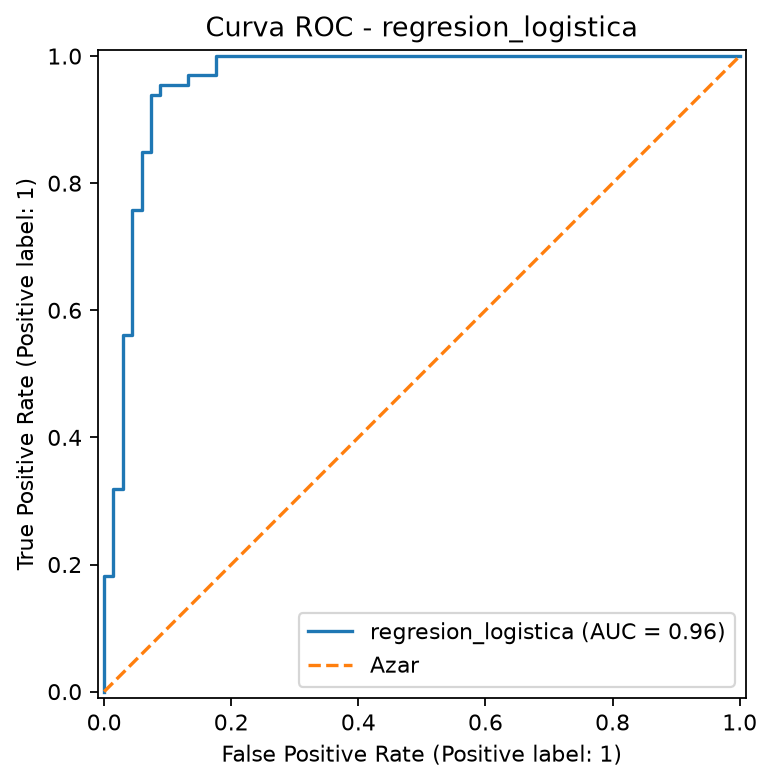

regresion_logistica_matriz_confusion.png


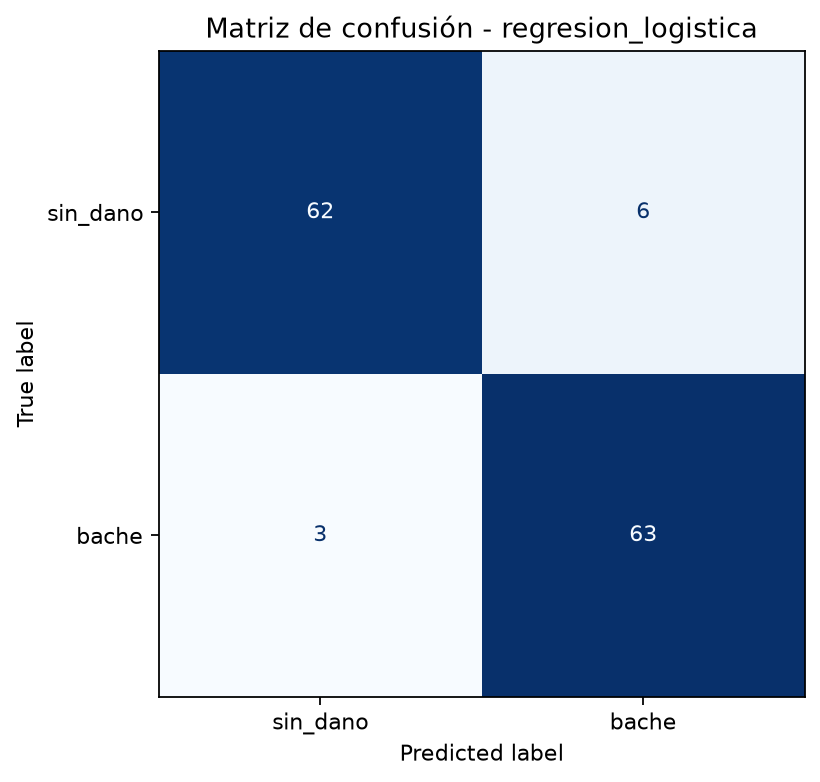

In [14]:
for figura in sorted((EVIDENCIAS / "modelos").glob("*.png")):
    print(figura.name)
    mostrar(figura, ancho=600)

### Lectura de los resultados

* La **regresión logística** obtiene mejores métricas de prueba (F1 0.9333, ROC-AUC 0.9615) y una validación cruzada más estable que Random Forest.
* **Random Forest** muestra una brecha amplia entre el F1 de entrenamiento (0.996) y el de validación (0.872): posible sobreajuste.
* La diferencia entre modelos no es estadísticamente concluyente: con cinco folds, el valor p más pequeño posible (0.0625) ya queda por encima de 0.05.
* En Random Forest domina `saturacion_media` (importancia 0.37), una dependencia que conviene validar con fotos de otras fuentes.

## 7. Trazabilidad en MLflow

Las ejecuciones se consultan desde el servidor local; si no está activo, se lee directamente `mlflow.db`.

In [15]:
import mlflow

try:
    mlflow.set_tracking_uri(MLFLOW_URI)
    ejecuciones = mlflow.search_runs(experiment_names=[EXPERIMENTO])
    print("Consultado el servidor:", MLFLOW_URI)
except Exception as error:
    print("Servidor no disponible, se lee mlflow.db directamente:", type(error).__name__)
    mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}")
    ejecuciones = mlflow.search_runs(experiment_names=[EXPERIMENTO])

basicas = [c for c in ["run_id", "tags.mlflow.runName", "status", "start_time"] if c in ejecuciones.columns]
metricas = [c for c in ejecuciones.columns if c.startswith("metrics.")]
print(len(ejecuciones), "ejecuciones en el experimento", EXPERIMENTO)
ejecuciones[basicas + metricas].sort_values("start_time", ascending=False).round(4)

Consultado el servidor: http://127.0.0.1:5000
9 ejecuciones en el experimento UrbanOS_Actividad5_Clasificacion


C:\Temp\ipykernel_19404\2392094179.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ejecuciones[basicas + metricas].sort_values("start_time", ascending=False).round(4)


,run_id,tags.mlflow.runName,status,start_time,metrics.wilcoxon_p_value,metrics.precision,metrics.f1,metrics.recall,metrics.cv_f1_media,metrics.accuracy,metrics.roc_auc,metrics.cv_f1_train_media,metrics.cv_f1_std,metrics.f1_cv_mejor
0,6dba78389f0845deb174f0185e6be5d3,comparacion_final,FINISHED,2026-10-18 19:35:36.843000+00:00,0.0625,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,94f0d4461e174db496c8843f497427ef,random_forest,FINISHED,2026-10-18 19:35:00.289000+00:00,NaN,0.8986,0.9185,0.9394,0.8718,0.9179,0.9599,0.9962,0.0436,NaN
2,7c12f8408aa84954b20b5e37487de50c,regresion_logistica,FINISHED,2026-10-18 19:34:30.583000+00:00,NaN,0.9130,0.9333,0.9545,0.9206,0.9328,0.9615,0.9191,0.0175,NaN
3,92891acea7d34914892d725bba0cb533,random_forest,FAILED,2026-10-18 19:23:47.903000+00:00,NaN,0.8986,0.9185,0.9394,0.8718,0.9179,0.9599,0.9962,0.0436,NaN
4,70a00e8e297d4b1a878655b8e6fce202,regresion_logistica,FINISHED,2026-10-18 19:23:16.515000+00:00,NaN,0.9130,0.9333,0.9545,0.9206,0.9328,0.9615,0.9191,0.0175,NaN
5,a9fdb87c3a624be9ad0c5a2ee90b0632,Random_Forest,FINISHED,2026-10-18 18:36:17.555000+00:00,NaN,0.8986,0.9185,0.9394,NaN,0.9179,NaN,NaN,NaN,0.8718
6,12847a03fd04412e8c7acd6671bd8082,Regresion_Logistica,FINISHED,2026-10-18 18:35:30.079000+00:00,NaN,0.9130,0.9333,0.9545,NaN,0.9328,NaN,NaN,NaN,0.9206
7,5a02487a649a4b0abfc42ffd574f8ad8,Random_Forest,FAILED,2026-10-18 15:46:37.846000+00:00,NaN,0.8986,0.9185,0.9394,NaN,0.9179,NaN,NaN,NaN,0.8718
8,4c3aebb0158f406ea84f999472972e5b,Regresion_Logistica,FINISHED,2026-10-18 15:45:48.778000+00:00,NaN,0.9130,0.9333,0.9545,NaN,0.9328,NaN,NaN,NaN,0.9206


In [16]:
parametros = [c for c in ejecuciones.columns if c.startswith("params.")]
ejecuciones[["tags.mlflow.runName"] + parametros].dropna(how="all", subset=parametros).T

,1,2,3,4,5,6,7,8
tags.mlflow.runName,random_forest,regresion_logistica,random_forest,regresion_logistica,Random_Forest,Regresion_Logistica,Random_Forest,Regresion_Logistica
params.scoring,f1,f1,f1,f1,NaN,NaN,NaN,NaN
params.semilla,42,42,42,42,42,42,42,42
params.version_numpy,2.4.6,2.4.6,2.4.6,2.4.6,NaN,NaN,NaN,NaN
params.n_registros_total,668,668,668,668,NaN,NaN,NaN,NaN
params.mejor_min_samples_leaf,1,NaN,1,NaN,1,NaN,1,NaN
params.version_python,3.11.9,3.11.9,3.11.9,3.11.9,NaN,NaN,NaN,NaN
params.n_registros_test,134,134,134,134,NaN,NaN,NaN,NaN
params.n_caracteristicas,16,16,16,16,NaN,NaN,NaN,NaN
params.mejor_max_depth,10,NaN,10,NaN,10,NaN,10,NaN


## 8. Reentrenamiento 

Con `REENTRENAR = True`, esta celda vuelve a ejecutar `fuentes/train.py`. Hacerlo crea ejecuciones nuevas en MLflow y sobrescribe `resultados/` y `evidencias/modelos/`.

In [17]:
if REENTRENAR:
    subprocess.run([sys.executable, str(RAIZ / "fuentes" / "train.py")], cwd=RAIZ, check=True)
else:
    print("REENTRENAR = False: se usan los resultados de la última ejecución.")

REENTRENAR = False: se usan los resultados de la última ejecución.


## 9. Conclusiones

1. La regresión logística es el modelo elegido: mejor F1 y ROC-AUC en prueba, validación cruzada estable y sin señales de sobreajuste.
2. Random Forest generaliza peor (brecha de 0.12 en F1 entre entrenamiento y validación), aun con la búsqueda de hiperparámetros.
3. La comparación estadística es exploratoria: cinco folds no alcanzan para demostrar una diferencia significativa.
4. Antes de usar el modelo en UrbanOS hay que validarlo con fotos propias y revisar la dependencia de `saturacion_media`.
5. Deuda técnica: datos sin versionado de imágenes, MLflow local con SQLite, entorno compartido con otros proyectos y sin pruebas automáticas.